# Cherry Leaf Powdery Mildew Detection

## Objective

Develop a machine learning system that classifies
cherry leaves as Healthy or Powdery Mildew using
image-derived features.

The project includes:

- Image exploration
- Feature engineering
- Exploratory data analysis
- Machine learning model comparison
- Model evaluation
- Streamlit deployment

## Import Needed Modules

In [3]:
# import modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Dataset Acquisition

The PlantVillage dataset was used for this project.

For this analysis, only Cherry Healthy and Cherry Powdery Mildew
images were selected.

In [5]:
# import data
import kagglehub

# download latest version
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Path to dataset files: /Users/jazlynsalazar/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3


In [7]:
# pull color images
color_path = os.path.join(dataset_path, "color")

for item in os.listdir(color_path):
    if "Cherry" in item:
        print(item)

Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy


In [8]:
# define paths
healthy_path = os.path.join(color_path, "Cherry_(including_sour)___healthy")
mildew_path = os.path.join(color_path, "Cherry_(including_sour)___Powdery_mildew")

# 2. Dataset Exploration

## Class Distribution

In [9]:
# check paths
print("Healthy:", len(os.listdir(healthy_path)))
print("Powdery Mildew:", len(os.listdir(mildew_path)))

Healthy: 854
Powdery Mildew: 1052


## Sample Images

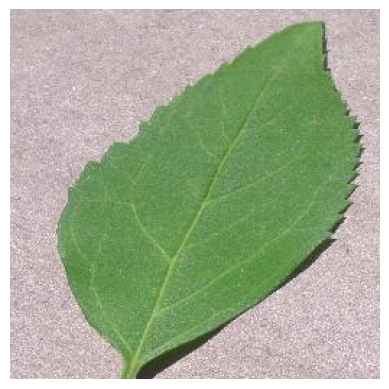

In [10]:
# display healthy sample image
sample_image = os.listdir(healthy_path)[0]
img = Image.open(os.path.join(healthy_path, sample_image))

plt.imshow(img)
plt.axis('off')
plt.show()

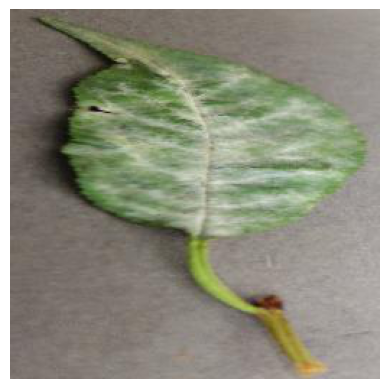

In [11]:
# display powdery mildew image
sample_image = os.listdir(mildew_path)[0]
img = Image.open(os.path.join(mildew_path, sample_image))

plt.imshow(img)
plt.axis('off')
plt.show()

# 3. Feature Engineering

## Extracted Features

The following features were extracted from each image:

- Width
- Height
- Average Red
- Average Green
- Average Blue
- Brightness

In [12]:
# feature extraction function

def extract_features(image_path):
    img = Image.open(image_path).convert("RGB")
    width, height = img.size
    img_array = np.array(img)
    avg_red = img_array[:, :, 0].mean()
    avg_green = img_array[:, :, 1].mean()
    avg_blue = img_array[:, :, 2].mean()
    brightness = img_array.mean()

    return {"width": width,
           "height": height, 
           "avg_red": avg_red, 
           "avg_green": avg_green,
           "avg_blue": avg_blue,
           "brightness": brightness}                             

In [14]:
# process healthy images
data = []

for file in os.listdir(healthy_path):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        image_path = os.path.join(healthy_path, file)
        features = extract_features(image_path)
        features["filename"] = file
        features["label"] = "Healthy"
        data.append(features)

In [15]:
# process powdery mildew images
for file in os.listdir(mildew_path):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        image_path = os.path.join(mildew_path, file)
        features = extract_features(image_path)
        features["filename"] = file
        features["label"] = "Powdery Mildew"
        data.append(features)

# 4. Building the Feature Dataset

In [16]:
# create the data frame
df = pd.DataFrame(data)
print(df.shape)

(1906, 8)


## Feature Dataset Overview
After feature extraction, a dataset was created in which each row represents a single cherry leaf image and each column represents either an extracted image feature or class label. 

This dataset serves as the foundation for both exploratory data analysis and machine learning model development

# 5. Exploratory Data Analysis

## Summary Statistics

In [17]:
df.head()

,width,height,avg_red,avg_green,avg_blue,brightness,filename,label
0,256,256,154.789154,167.286896,138.642548,153.572866,517b275d-ef1e-49b1-be9e-c7dcc95dab00___JR_HL 3...,Healthy
1,256,256,154.818268,159.212997,138.568665,150.866643,df2935bd-3e9b-4da1-8bba-5a449503f773___JR_HL 9...,Healthy
2,256,256,121.220184,131.606964,108.393021,120.406723,9b15b47c-53e0-4873-b51c-d2b6e316d56c___JR_HL 4...,Healthy
3,256,256,172.240829,176.253296,148.819153,165.771093,f9236ca5-ea7c-4a87-bac0-396883f95ba6___JR_HL 9...,Healthy
4,256,256,135.593262,138.188736,115.547058,129.776352,c655f45b-4c63-406c-8f6e-e3c4f9e85b06___JR_HL 9...,Healthy


In [18]:
df["label"].value_counts()

label
Powdery Mildew    1052
Healthy            854
Name: count, dtype: int64

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1906 entries, 0 to 1905
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   width       1906 non-null   int64  
 1   height      1906 non-null   int64  
 2   avg_red     1906 non-null   float64
 3   avg_green   1906 non-null   float64
 4   avg_blue    1906 non-null   float64
 5   brightness  1906 non-null   float64
 6   filename    1906 non-null   object 
 7   label       1906 non-null   object 
dtypes: float64(4), int64(2), object(2)
memory usage: 119.3+ KB


In [20]:
df.describe()

,width,height,avg_red,avg_green,avg_blue,brightness
count,1906.0,1906.0,1906.000000,1906.000000,1906.000000,1906.000000
mean,256.0,256.0,126.062689,132.726299,111.533087,123.440692
std,0.0,0.0,20.902489,20.386488,20.957773,19.909142
min,256.0,256.0,73.128143,76.196411,53.718369,68.286718
25%,256.0,256.0,111.763351,119.524792,97.517353,110.809828
50%,256.0,256.0,122.806953,130.282433,108.267448,120.139717
75%,256.0,256.0,137.247055,144.542721,124.087254,134.031485
max,256.0,256.0,203.891144,209.626724,190.212158,199.790070


## Summary Statistics Interpretation
The RGB and brightness variables show meaningful variation across the dataset, suggesting that leaf images differ substantially in their visual characteristics. 

Image width and height show no variation because all images were standardized to 256 x 256 pixels before analysis. 

In [21]:
df.groupby("label").mean(numeric_only = True)

,width,height,avg_red,avg_green,avg_blue,brightness
label,,,,,,
Healthy,256.0,256.0,138.313961,144.489326,121.171011,134.658099
Powdery Mildew,256.0,256.0,116.117265,123.177227,103.709145,114.334546


## Class Comparison
Healthy leaves have higher average values for red, green, blue and brightness compared to powdery mildew leaves. 

These differences suggest that infection alters the visual appearance of the leaf and that color-based features may be useful for disease classification. 

## Feature Distributions

### Healthy vs Powdery Mildew Comparison

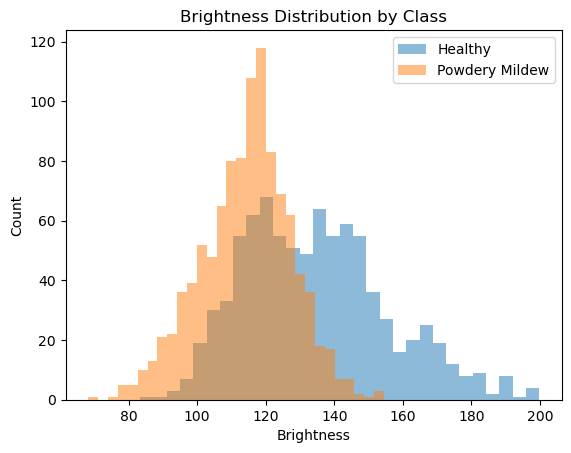

In [22]:
# initial visualization
for label in df["label"].unique():
    subset = df[df["label"] == label]
    plt.hist(subset["brightness"], alpha = 0.5, bins = 30, label = label)

plt.xlabel("Brightness")
plt.ylabel("Count")
plt.title("Brightness Distribution by Class")
plt.legend()
plt.show()

##### Histogram Interpretation
* Healthy leaves tend to have higher brightness values, with a peak around 130 - 145
* Powdery mildew leaves tend to have lower brightness values, with a peak around 110-120
* There is some overlap between about 105-135, meaning brightness alone will not perfectly separate the classes
* However, the two distributions are clearly shifted relative to each other, suggesting that brightness contains useful information for classification

The brightness distributions for healthy and powdery mildew cherry leaves are noticeably different. Healthy leaves generally have higher brightness values, while powdery mildew leaves tend to be darker overall. Although there is overlap between the two classes, the distributions are shifted enough to suggest that brightness may be a useful feature for distinguishing healthy from infected leaves. Because the classes are not completely separated, additional image features will likely be needed for accurate classification. 

In [23]:
# save data frame
df.to_csv("cherry_features.csv", index = False)

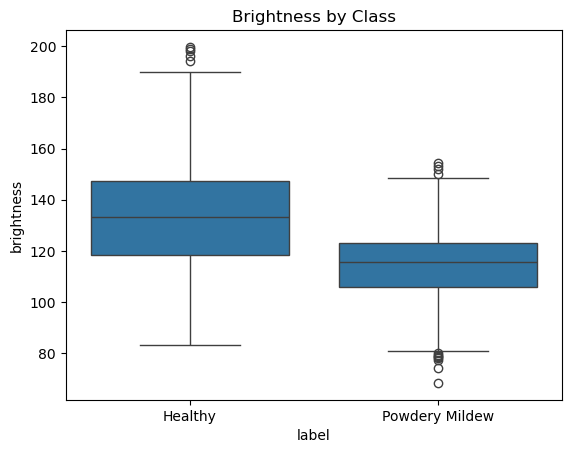

In [24]:
import seaborn as sns
sns.boxplot(data = df, x = "label", y = "brightness")
plt.title("Brightness by Class")
plt.show()

##### Boxplot Interpretation
* The median brightness is higher for Healthy leaves, around 133
* The median brightness for Powdery Mildew leaves is lower, around 116
* The middle 50% of Healthy images is generally brighter around the middle 50% of Powdery Mildew Images
* There is still overlap between the two groups, so brightness alone will not perfectly identify disease
* Healthy images have a larger spread, meaning brightness varies more among healthy leaves
* Both groups contain a few outliers

The boxplot shows that healthy cherry leaves generally have higher brightness values than leaves affected by powdery mildew. The median brightness of healthy leaves is noticeably higher, while powdery mildew leaves tend to cluster around lower brightness values. There is some overlap between the two classes, indicating that brightness alone is not sufficient for perfect classification. However, the difference in median values suggests that brightness may be a useful feature for distinguishing healthy and infected leaves. Healthy leaves also exhibit greater variability in brightness, as shown by the wider distribution of values. 

In [25]:
df.groupby("label")["brightness"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Healthy,854.0,134.658099,21.003372,83.311890,118.353200,133.368818,147.370179,199.790070
Powdery Mildew,1052.0,114.334546,13.235254,68.286718,105.997482,115.620522,123.082876,154.494512


##### Summary Statistics Interpretation
* Healthy leaves are about 20 brightness units brighter on average
* The median values tell the same story, so the difference is not being driven by a few images
* Healthy leaves show more variation in brightness (std = 21) than powdery mildew leaves (std = 13.24)

Analysis of image brightness revealed clear differences between healthy and powdery mildew cherry leaves. Healthy leaves had a higher average brightness (134.66) compared to powdery mildew leaves (114.33). The median brightness values showed a similar pattern, indicating that healthy images are generally brighter overall. Healthy leaves also exhibited greater variability in brightness, with a standard deviation of 21 compared to 13.24 for infected leaves. While the distributions overlap, brightness appears to be a useful feature for distinguishing between healthy and diseased leaves. 

In [56]:
# encode the labels
df["target"] = df["label"].map({"Healthy": 0, "Powdery Mildew": 1})
df[["label", "target"]].drop_duplicates()
df["target"].value_counts()

target
1    1052
0     854
Name: count, dtype: int64

## Label Encoding
The categorical labels were converted into numerical values to support machine learning model development. 
* Healthy = 0
* Powdery Mildew = 1

## Training, Validation, and Testing Sets

In [27]:
# create train, valudation, and test sets
# first split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# second split: split the remaining 30% into 15% validation and 15% test
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(valid_df))
print("Testing:", len(test_df))

Training: 1334
Validation: 286
Testing: 286


In [28]:
print(train_df["label"].value_counts())
print(valid_df["label"].value_counts())
print(test_df["label"].value_counts())

label
Powdery Mildew    736
Healthy           598
Name: count, dtype: int64
label
Powdery Mildew    158
Healthy           128
Name: count, dtype: int64
label
Powdery Mildew    158
Healthy           128
Name: count, dtype: int64


In [29]:
# create image filepaths 
color_path = "/Users/jazlynsalazar/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color"

def make_filepath(row):
    if row["label"] == "Healthy":
        return os.path.join(color_path, "Cherry_(including_sour)___healthy", row["filename"])
    else:
        return os.path.join(color_path, "Cherry_(including_sour)___Powdery_mildew", row["filename"])

df["filepath"] = df.apply(make_filepath, axis=1)

In [30]:
df[["filepath", "label"]].head()

,filepath,label
0,/Users/jazlynsalazar/.cache/kagglehub/datasets...,Healthy
1,/Users/jazlynsalazar/.cache/kagglehub/datasets...,Healthy
2,/Users/jazlynsalazar/.cache/kagglehub/datasets...,Healthy
3,/Users/jazlynsalazar/.cache/kagglehub/datasets...,Healthy
4,/Users/jazlynsalazar/.cache/kagglehub/datasets...,Healthy


# 7. Data Preparation
Before the model training, the dataset was divided into training, validation, and testing subsets. Stratified sampling was used to preserve class proportions across all subsets. 

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df[["avg_red", "avg_green", "avg_blue", "brightness"]]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Dataset Split Summary
The dataset was divided into:
* Training Set: 1,334 images
* Validation Set: 286 images
* Testing Set: 286 images

Class balance was maintained across all subsets to reduce bias during model evaluation. 

# 8. Model Development

## Why These Models?
Three machine learning algorithms were evaluated and compared. 
* Logistic Regression was used as a baseline classifier
* Random forest was selected because it can capture nonlinear relationships among features
* Support Vector Machine (SVM) was selected because it performs well on classification problems involving relatively small feature sets.

The goal was to determine which model performed best using the extracted image features. 

## Logistic Regression

In [33]:
# logistic regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

from sklearn.metrics import accuracy_score

print("Logistic Regression:",
      accuracy_score(y_test, predictions))

Logistic Regression: 0.7146596858638743


### Logistic Regression Results
Logistic Regression achieved an accuracy of approximately 71.5%. 

This result demonstrates that the extracted color and brightness features contain useful information for disease classification.

## Random Forest

In [32]:
# random forest

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))

Accuracy: 0.725130890052356


### Random Forest Results
Random Forest achieved an accuracy of approximately 72.5%. 

The model slightly outperformed Logistic Regression, suggesting that nonlinear relationships among features improve classification performance. 

## Support Vector Machine

In [34]:
# support vector machine (SVM)
from sklearn.svm import SVC

model = SVC()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

from sklearn.metrics import accuracy_score

print("SVM:",
      accuracy_score(y_test, predictions))

SVM: 0.7486910994764397


### Support Vector Machine Results
The Support Vector Machine achieved the highest accuracy at approximately 74.9%. 

Because it achieved the best overall performance, the SVM was selected as the final model for deployment. 

# 9. Model Comparison



| **Model** | **Accuracy** |
| ------| -------- | 
| Logistic Regression | 71.5% |
| Random Forest | 72.5% | 
| Support Vector Machine | 74.9% |

The Support Vector Machine achieved the highest accuracy and was selected as the final model for deployment. 

# 10. Model Evaluation

In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      0.56      0.66       171
           1       0.72      0.91      0.80       211

    accuracy                           0.75       382
   macro avg       0.77      0.73      0.73       382
weighted avg       0.76      0.75      0.74       382



## Confusion Matrix

The confusion matrix shows that the model correctly identified most powdery mildew cases while producing a relatively small number of false negatives. 

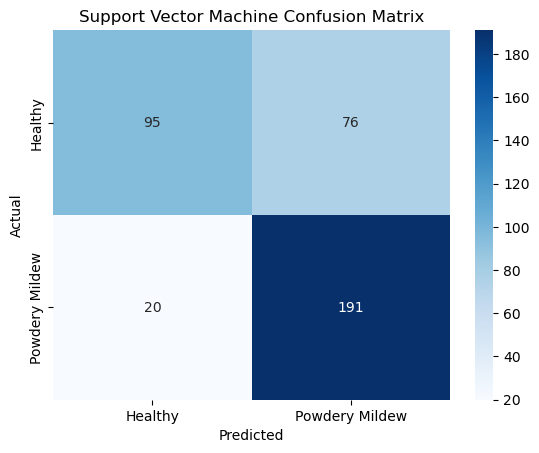

In [58]:
# create a confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Healthy", "Powdery Mildew"], yticklabels=["Healthy", "Powdery Mildew"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Support Vector Machine Confusion Matrix")
plt.show()

### Classification Report Interpretation

An SVM classifier was trained using average RGB values and image brightness as input features. The model achieved an accuracy of 72.5% on the test dataset. This result indicates that color and brightness characteristics contain useful information for distinguishing healthy cherry leaves from leaves affected by powdery mildew. However, the accuracy also suggests that additional image information may be needed for optimal performance. Future improvements could include extracting texture features or using a convolutional neural network to analyze the full image rather than summary statistics. 

Three machine learning models were compared using average RGB values and image brightness as predictors. Logistic Regression achieved an accuracy of 71.5%, Random Forest achieved 72.5%, and Support Vector Machine (SVM) achieved 74.9%. The SVM produced the highest overall accuracy and was therefore selected as the best-performing model. Analysis of the confusion matrix and classification metrics showed that the model was particularly effective at identifying powdery mildew leaves, achieving a recall of 0.91 for the infected class. This is desirable because missing diseased plants can have more consequences than producing false positives. These results suggest that color and brightness characteristics contain useful information for distinguishing healthy and diseased cherry leaves, although additional image features would likely improve performance. 

In [40]:
# make predictions more readable
sample_predictions = loaded_model.predict(X_test[:5])

for pred in sample_predictions:
    if pred == 0:
        print("Healthy")
    else:
        print("Powdery Mildew")

Powdery Mildew
Healthy
Powdery Mildew
Powdery Mildew
Powdery Mildew


In [41]:
# save features list
features = ["avg_red", "avg_green", "avg_blue", "brightness"]

In [55]:
# check feature importance
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

for feature, importance in zip(X.columns, rf_model.feature_importances_):
    print(feature, round(importance, 3))

avg_red 0.272
avg_green 0.296
avg_blue 0.181
brightness 0.251


In [43]:
print(df.columns)

Index(['width', 'height', 'avg_red', 'avg_green', 'avg_blue', 'brightness',
       'filename', 'label', 'target', 'filepath'],
      dtype='object')


In [44]:
df.to_csv("cherry_features.csv", index=False)

# 11. Model Export

The final SVM model was saved for deployment within the Streamlit application. 

In [46]:
plt.savefig("confusion_matrix.png", bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [50]:
import joblib

joblib.dump(model, "svm_model.pkl")

['svm_model.pkl']

# 12. Streamlit Deployment

A Streamlit dashboard was developed to provide: 
* Dataset exploration
* Feature analysis
* Correlation analysis
* Model comparison
* Model evaluation
* Live image prediction

Users can upload new cherry leaf images and receive real-time classification results along with model confidence estimates. 

# 13. Conclusions

## Key Findings

- The dataset consisted of 1,906 cherry leaf images.
- RGB and brightness features provided meaningful information for classification.
- Three machine learning models were evaluated.
- The Support Vector Machine achieved the highest accuracy of 74.9%.
- The final model was successfully deployed through a Streamlit dashboard.

## Future Work

- Incorporate additional image features.
- Explore convolutional neural networks (CNNs).
- Expand the dataset.
- Deploy the application online. 